# Triplet Loss 대조학습 vs 원본 임베딩 비교 (Colab GPU)

**목표**: 간단한 데이터셋(Fashion-MNIST)에 대해
1. **원본(Original) 임베딩** — 아무 학습도 하지 않은 상태 (원본 픽셀 / 랜덤 초기화 인코더)
2. **Triplet Loss로 대조학습한 임베딩**

두 임베딩 공간을 t-SNE로 2D 시각화하고, 정량 지표(kNN 정확도, 실루엣 점수, 클래스 내/간 거리 비율)로 비교합니다.

> 실행 전: `런타임 → 런타임 유형 변경 → T4 GPU` 선택

In [1]:
# GPU 확인
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ GPU가 아닙니다. 런타임 → 런타임 유형 변경 → GPU 를 선택하세요.")

device: cpu
⚠️ GPU가 아닙니다. 런타임 → 런타임 유형 변경 → GPU 를 선택하세요.


In [2]:
import numpy as np, matplotlib.pyplot as plt, time
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import silhouette_score

torch.manual_seed(0); np.random.seed(0)

## 1. 데이터셋 준비 (Fashion-MNIST)
28×28 흑백 이미지, 10개 클래스. 빠른 실습을 위해 학습 10,000장, 평가 2,000장만 사용합니다.

0.1%

0.2%

0.4%

0.5%

0.6%

...

98.6%

99.3%

100.0%

100.0%

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


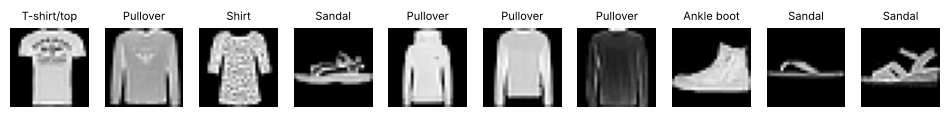

In [3]:
tf = transforms.ToTensor()
train_full = datasets.FashionMNIST("./data", train=True,  download=True, transform=tf)
test_full  = datasets.FashionMNIST("./data", train=False, download=True, transform=tf)

N_TRAIN, N_TEST = 10000, 2000
train_ds = Subset(train_full, np.random.choice(len(train_full), N_TRAIN, replace=False))
test_ds  = Subset(test_full,  np.random.choice(len(test_full),  N_TEST,  replace=False))

train_loader = DataLoader(train_ds, batch_size=256, shuffle=True,  num_workers=2, drop_last=True)
test_loader  = DataLoader(test_ds,  batch_size=512, shuffle=False, num_workers=2)

CLASSES = train_full.classes
print(CLASSES)

# 샘플 미리보기
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for ax, i in zip(axes, range(10)):
    img, y = train_ds[i]
    ax.imshow(img[0], cmap="gray"); ax.set_title(CLASSES[y], fontsize=8); ax.axis("off")
plt.show()

## 2. 인코더 정의
작은 CNN → 64차원 임베딩(L2 정규화). 같은 구조를 **학습 전(원본)** 과 **Triplet 학습 후** 두 번 사용해 비교합니다.

In [4]:
class Encoder(nn.Module):
    def __init__(self, dim=64):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),   # 14x14
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),  # 7x7
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
        )
        self.fc = nn.Sequential(nn.Flatten(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, dim))

    def forward(self, x):
        z = self.fc(self.conv(x))
        return F.normalize(z, dim=1)   # 단위 구 위로 정규화 → 거리 비교가 안정적

@torch.no_grad()
def extract(model, loader):
    model.eval()
    zs, ys = [], []
    for x, y in loader:
        zs.append(model(x.to(device)).cpu()); ys.append(y)
    return torch.cat(zs).numpy(), torch.cat(ys).numpy()

## 3. Triplet Loss + Batch-All 마이닝

$$\mathcal{L} = \max\big(d(a,p) - d(a,n) + \text{margin},\ 0\big)$$

- **a**nchor, **p**ositive(같은 클래스), **n**egative(다른 클래스)
- 배치 안에서 만들 수 있는 **모든 (a, p, n) 조합**의 손실을 계산하고, margin을 아직 못 넘긴(활성) triplet만 평균합니다 (batch-all).
- ⚠️ 참고: 가장 어려운 triplet만 쓰는 *batch-hard* 마이닝은 랜덤 초기화에서 바로 시작하면 모든 임베딩이 한 점으로 **붕괴**(loss ≈ margin, active 100%)하기 쉽습니다. 실제로 이 노트북에서 batch-hard로 먼저 돌려보니 loss가 0.30에서 멈췄고, batch-all로 바꾸니 정상 학습되었습니다.

In [5]:
def batch_all_triplet_loss(z, y, margin=0.3):
    # z: (B, D) 정규화된 임베딩, y: (B,)
    dist = torch.cdist(z, z)                               # (B, B) 유클리드 거리
    same = y[:, None] == y[None, :]                        # 같은 클래스 마스크
    eye  = torch.eye(len(y), dtype=torch.bool, device=z.device)
    pos_mask = same & ~eye                                 # (a, p) 쌍
    neg_mask = ~same                                       # (a, n) 쌍

    # 배치 안의 모든 (a, p, n) 조합을 한 번에: (B, B, B)
    loss  = dist[:, :, None] - dist[:, None, :] + margin   # d(a,p) - d(a,n) + margin
    valid = pos_mask[:, :, None] & neg_mask[:, None, :]    # p는 같은 클래스, n은 다른 클래스
    loss  = F.relu(loss) * valid

    n_active = (loss > 1e-8).sum()                         # margin을 아직 못 넘긴 triplet 수
    return loss.sum() / n_active.clamp(min=1), n_active.float() / valid.sum()   # (loss, active 비율)

## 4. 원본(학습 전) 임베딩 추출
학습 전 상태 두 가지를 "원본"으로 저장합니다.
- **Raw pixels**: 784차원 픽셀 벡터 그대로
- **Untrained encoder**: 랜덤 초기화 인코더의 64차원 출력

In [6]:
model = Encoder(dim=64).to(device)

# (a) 원본 픽셀
X_pix, y_test = [], []
for x, y in test_loader:
    X_pix.append(x.view(len(x), -1)); y_test.append(y)
X_pix = torch.cat(X_pix).numpy(); y_test = torch.cat(y_test).numpy()

# (b) 학습 전 인코더
Z_before, _ = extract(model, test_loader)
print("raw pixels:", X_pix.shape, "| untrained encoder:", Z_before.shape)

raw pixels: (2000, 784) | untrained encoder: (2000, 64)


## 5. Triplet Loss로 대조학습

epoch  1 | loss 0.2744 | active triplets 26.37% | 16.4s


epoch  2 | loss 0.2735 | active triplets 15.92% | 15.0s


epoch  3 | loss 0.2654 | active triplets 13.49% | 15.4s


epoch  4 | loss 0.2653 | active triplets 11.65% | 14.7s


epoch  5 | loss 0.2596 | active triplets 10.43% | 14.8s


...

epoch 26 | loss 0.1619 | active triplets 0.51% | 14.9s


epoch 27 | loss 0.1462 | active triplets 0.36% | 15.1s


epoch 28 | loss 0.1428 | active triplets 0.27% | 15.0s


epoch 29 | loss 0.1364 | active triplets 0.23% | 15.6s


epoch 30 | loss 0.1282 | active triplets 0.22% | 14.4s


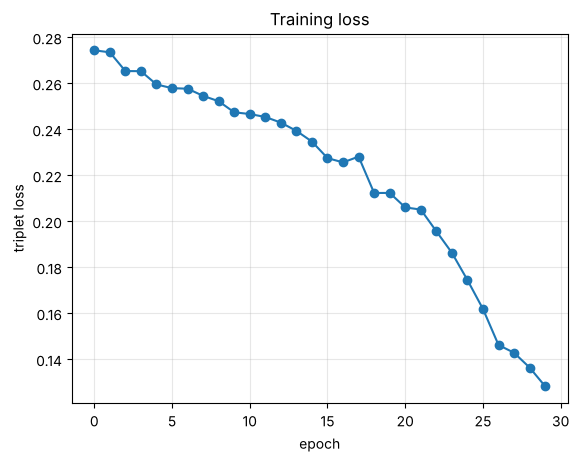

In [7]:
EPOCHS, MARGIN = 30, 0.3
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
history = []

for ep in range(1, EPOCHS + 1):
    model.train(); t0 = time.time()
    tot, act, n = 0.0, 0.0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss, frac = batch_all_triplet_loss(model(x), y, MARGIN)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item(); act += frac.item(); n += 1
    sched.step()
    history.append(tot / n)
    print(f"epoch {ep:2d} | loss {tot/n:.4f} | active triplets {act/n:.2%} | {time.time()-t0:.1f}s")

plt.plot(history, marker="o"); plt.xlabel("epoch"); plt.ylabel("triplet loss"); plt.title("Training loss"); plt.grid(alpha=.3); plt.show()

In [8]:
Z_after, _ = extract(model, test_loader)
print("trained encoder:", Z_after.shape)

trained encoder: (2000, 64)


## 6. 임베딩 시각화 비교 (t-SNE)
세 공간을 같은 조건으로 t-SNE 2D 투영합니다. 색 = 정답 클래스.

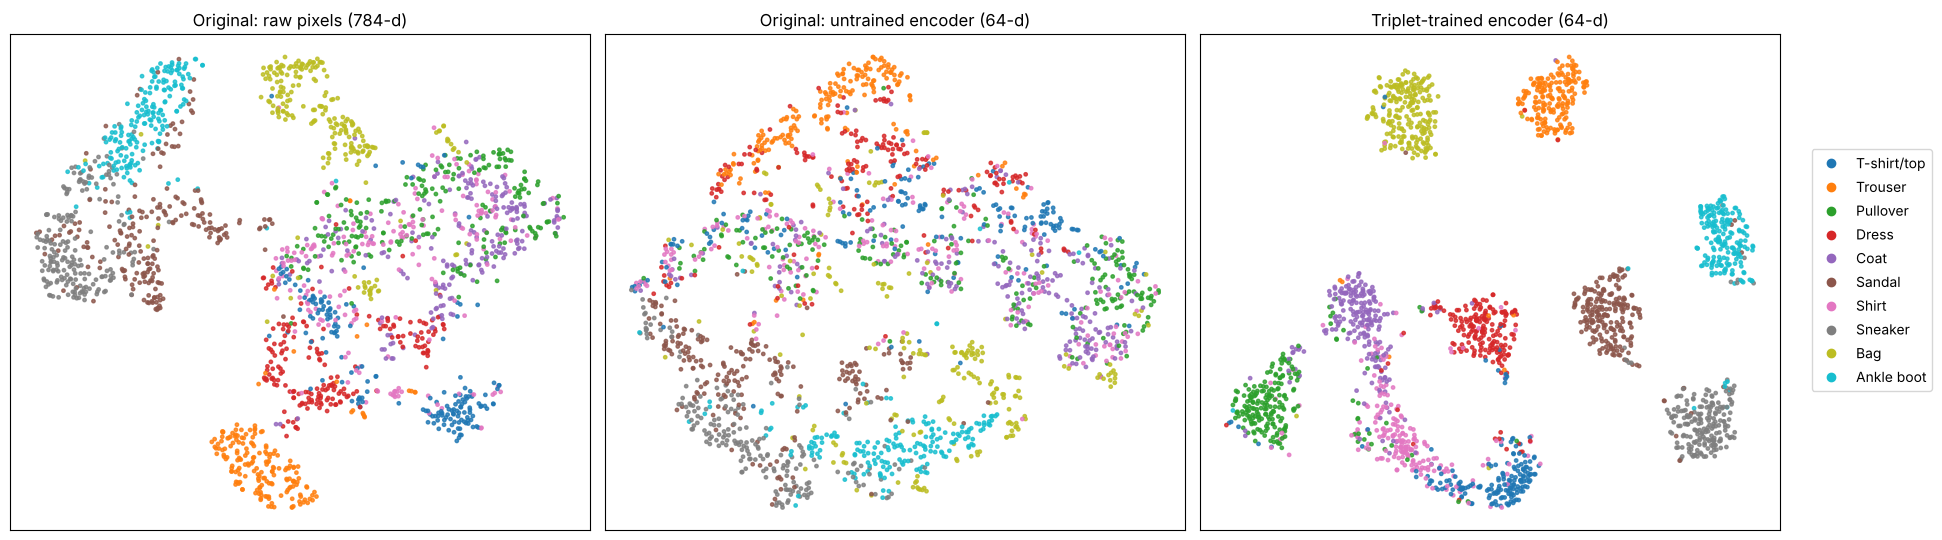

In [9]:
def tsne(X, seed=0):
    return TSNE(n_components=2, init="pca", perplexity=30, random_state=seed).fit_transform(X)

spaces = {
    "Original: raw pixels (784-d)": X_pix,
    "Original: untrained encoder (64-d)": Z_before,
    "Triplet-trained encoder (64-d)": Z_after,
}
proj = {k: tsne(v) for k, v in spaces.items()}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (name, P) in zip(axes, proj.items()):
    sc = ax.scatter(P[:, 0], P[:, 1], c=y_test, cmap="tab10", s=6, alpha=.8)
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(i), label=CLASSES[i]) for i in range(10)]
fig.legend(handles=handles, loc="center right", bbox_to_anchor=(1.08, 0.5))
plt.tight_layout(); plt.show()

## 7. 정량 비교
- **kNN 정확도**: 임베딩 공간에서 이웃만 보고 분류가 되는가 (5-fold 평균)
- **실루엣 점수** (−1~1): 같은 클래스는 뭉치고 다른 클래스는 떨어져 있는가
- **클래스 내 / 클래스 간 평균 거리 비율**: 작을수록 좋음

In [10]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import pairwise_distances

def metrics(X, y):
    knn = cross_val_score(KNeighborsClassifier(n_neighbors=5), X, y, cv=5).mean()
    sil = silhouette_score(X, y, sample_size=1500, random_state=0)
    D = pairwise_distances(X); same = y[:, None] == y[None, :]
    off = ~np.eye(len(y), dtype=bool)
    ratio = D[same & off].mean() / D[~same].mean()
    return knn, sil, ratio

print(f"{'space':40s} {'kNN acc':>8s} {'silhouette':>11s} {'intra/inter':>12s}")
rows = {}
for name, X in spaces.items():
    k, s, r = metrics(X, y_test); rows[name] = (k, s, r)
    print(f"{name:40s} {k:8.3f} {s:11.3f} {r:12.3f}")

space                                     kNN acc  silhouette  intra/inter


Original: raw pixels (784-d)                0.773       0.042        0.757
Original: untrained encoder (64-d)          0.641      -0.085        0.785


Triplet-trained encoder (64-d)              0.891       0.496        0.379


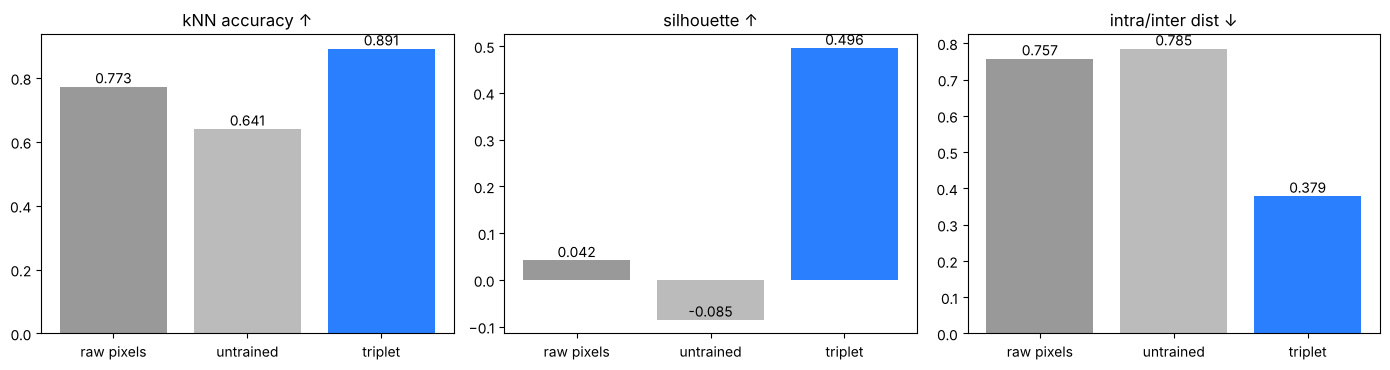

In [11]:
# 막대그래프로 한눈에
names = list(rows); short = ["raw pixels", "untrained", "triplet"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, i, title in zip(axes, range(3), ["kNN accuracy ↑", "silhouette ↑", "intra/inter dist ↓"]):
    vals = [rows[n][i] for n in names]
    ax.bar(short, vals, color=["#999", "#bbb", "#2a7fff"]); ax.set_title(title)
    for j, v in enumerate(vals): ax.text(j, v, f"{v:.3f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 8. 거리 분포 비교
"같은 클래스 쌍"과 "다른 클래스 쌍"의 거리 히스토그램. 학습 후에는 두 분포가 분리되어야 합니다.

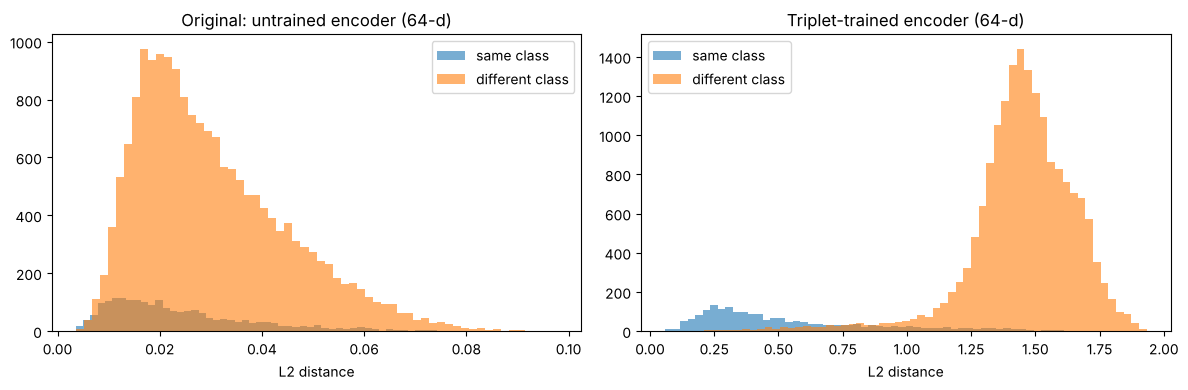

In [12]:
def pair_dists(X, y, n=20000):
    i = np.random.randint(0, len(X), n); j = np.random.randint(0, len(X), n)
    keep = i != j; i, j = i[keep], j[keep]
    d = np.linalg.norm(X[i] - X[j], axis=1); same = y[i] == y[j]
    return d[same], d[~same]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ["Original: untrained encoder (64-d)", "Triplet-trained encoder (64-d)"]):
    ps, ng = pair_dists(spaces[name], y_test)
    ax.hist(ps, bins=60, alpha=.6, label="same class"); ax.hist(ng, bins=60, alpha=.6, label="different class")
    ax.set_title(name); ax.set_xlabel("L2 distance"); ax.legend()
plt.tight_layout(); plt.show()

## 9. 쿼리 이미지로 최근접 이웃 검색 비교
같은 쿼리에 대해 원본 공간과 Triplet 공간에서 가장 가까운 5장을 보여줍니다.

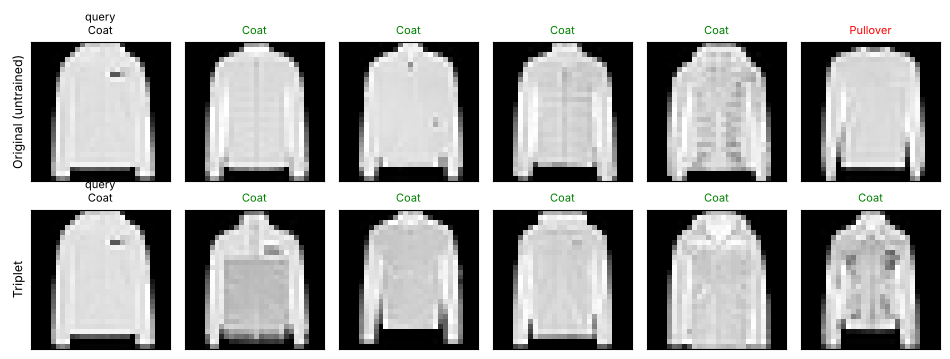

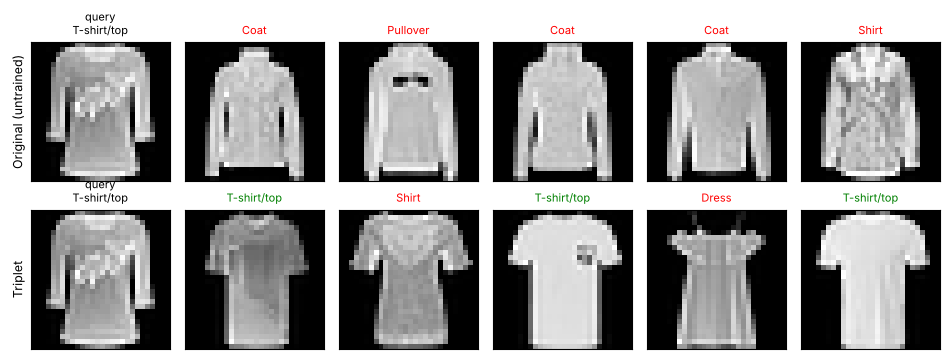

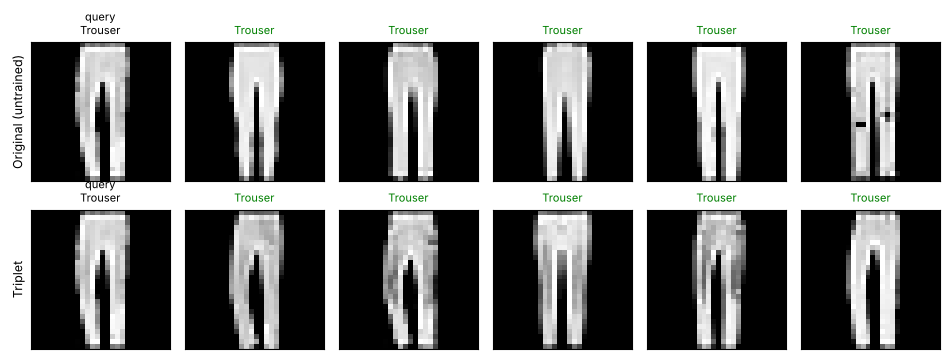

In [13]:
X_img = np.stack([test_ds[i][0][0].numpy() for i in range(len(test_ds))])

def show_nn(q, k=5):
    fig, axes = plt.subplots(2, k + 1, figsize=(1.6 * (k + 1), 3.6))
    for r, (name, X) in enumerate([("Original (untrained)", Z_before), ("Triplet", Z_after)]):
        d = np.linalg.norm(X - X[q], axis=1); d[q] = np.inf
        nn_idx = np.argsort(d)[:k]
        axes[r, 0].imshow(X_img[q], cmap="gray"); axes[r, 0].set_title(f"query\n{CLASSES[y_test[q]]}", fontsize=8)
        axes[r, 0].set_ylabel(name, fontsize=9)
        for c, j in enumerate(nn_idx, 1):
            ok = y_test[j] == y_test[q]
            axes[r, c].imshow(X_img[j], cmap="gray")
            axes[r, c].set_title(CLASSES[y_test[j]], fontsize=8, color="green" if ok else "red")
        for ax in axes[r]: ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()

for q in np.random.choice(len(y_test), 3, replace=False):
    show_nn(int(q))

## 정리
| | 원본(학습 전) | Triplet 대조학습 후 |
|---|---|---|
| t-SNE | 클래스가 섞여 있음 | 클래스별로 뚜렷한 군집 |
| kNN / 실루엣 | 낮음 | 크게 상승 |
| 거리 분포 | same/different 겹침 | 두 분포가 분리 |

**실험해 볼 것**: `MARGIN`(0.1~1.0), `EPOCHS`, 임베딩 차원 `dim`, 마이닝 방식(batch-all → semi-hard / batch-hard: 붕괴가 일어나는지 확인)을 바꿔 보며 변화를 관찰하세요.